# Exercises XP Ninja — Image Compression with K-Means and PCA

In this exercise, I compress an image by reducing its colors with K-Means, and I reduce a 2D dataset to 1D with PCA. I follow the course's pre-filled Colab notebook and complete its TODO parts.

### What I learn here
- Image compression with K-Means on RGB pixels.
- Dimensionality reduction with PCA.

## How to run in Colab
1. Open [Google Colab](https://colab.research.google.com) → **File → Upload notebook** → choose this file.
2. I keep `bird_small_and_ex7data1.zip` in my `C:\Users\sivan\Datasets` folder. It holds the two course files [bird_small.mat](https://github.com/fengdu78/Coursera-ML-AndrewNg-Notes/blob/master/code/ex7-kmeans%20and%20PCA/data/bird_small.mat) and `ex7data1.mat` (from the same course folder).
3. I run the cells from top to bottom. When the upload cell opens a file picker, I choose `bird_small_and_ex7data1.zip`.

In [ ]:
from google.colab import files
# I import Colab's tool for uploading files from my computer.
uploaded = files.upload()
# I open a file picker and choose "bird_small_and_ex7data1.zip".
!unzip "bird_small_and_ex7data1.zip"
# I extract bird_small.mat and ex7data1.mat from the zip into Colab.

### Provided helpers
The course provides these K-Means functions and says not to modify them, so I use them exactly as given:
- `init_centroids` picks K random pixels as the starting colors.
- `find_closest_centroids` gives each pixel the index of its closest centroid.
- `compute_centroids` moves each centroid to the mean of its pixels.
- `run_k_means` repeats the last two steps `max_iters` times.

In [1]:
import numpy as np

def init_centroids(X, K, rng=None):
    rng = np.random.default_rng() if rng is None else rng
    m = X.shape[0]
    idx = rng.choice(m, size=K, replace=False)
    return X[idx].astype(float)

def find_closest_centroids(X, centroids):
    diffs = X[:, None, :] - centroids[None, :, :]
    d2 = np.sum(diffs * diffs, axis=2)
    return np.argmin(d2, axis=1)

def compute_centroids(X, idx, K, rng=None):
    m, n = X.shape
    C = np.zeros((K, n), dtype=float)
    rng = np.random.default_rng() if rng is None else rng
    for k in range(K):
        pts = X[idx == k]
        if pts.size == 0:
            C[k] = X[rng.integers(0, m)]
        else:
            C[k] = pts.mean(axis=0)
    return C

def run_k_means(X, init_C, max_iters=10, rng=None):
    K = init_C.shape[0]
    C = init_C.copy().astype(float)
    history = [C.copy()]
    idx = None
    for _ in range(max_iters):
        idx = find_closest_centroids(X, C)
        C = compute_centroids(X, idx, K, rng=rng)
        history.append(C.copy())
    return C, idx, history

## Task 1 - Load and preprocess image from `bird_small.mat`

In this task, I load the image with `scipy.io.loadmat`, normalize its values to [0, 1] by dividing by 255, and reshape it into a 2D array with one row per pixel and one column per RGB color channel.

### What I learn here
- An image is a 3D array: height × width × 3 colors.
- I reshape it so each pixel becomes one row of 3 numbers.

In [2]:
from scipy.io import loadmat
import matplotlib.pyplot as plt
import numpy as np

mat = loadmat('bird_small.mat')
# The variable is usually 'A' with shape (H, W, 3)
A = mat.get('A', None)
if A is None:
    # Fallback: try common keys or raise
    for k in mat.keys():
        if isinstance(mat[k], np.ndarray) and mat[k].ndim == 3 and mat[k].shape[2] == 3:
            A = mat[k]; break
if A is None:
    raise ValueError('Could not find 3D RGB array in bird_small.mat')

# I divide by 255 so every color value is between 0 and 1.
A_norm = A / 255
# I reshape to (height * width, 3): one row per pixel, columns R, G, B.
# -1 tells NumPy to calculate the number of rows by itself.
X_img = A_norm.reshape(-1, 3)
print('Image shape:', A.shape, 'Pixels shape:', X_img.shape)
print('Min and max after normalizing:', X_img.min(), X_img.max())

Image shape: (128, 128, 3) Pixels shape: (16384, 3)
Min and max after normalizing: 0.023529411764705882 1.0


## Task 2 - K-Means image compression

In this task, I choose the number of colors K and the number of iterations, initialize the centroids randomly with `init_centroids`, and run K-Means. Then I recover the image by giving each pixel the color of its closest centroid (with `find_closest_centroids`), and I display the compressed image.

### What I learn here
- The K centroids become a small color palette.
- Each pixel is replaced by its closest palette color.

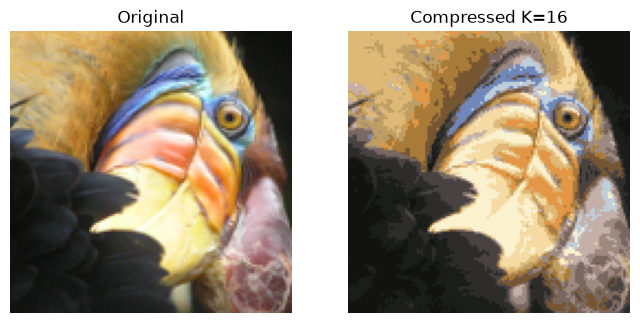

Colors in the original image: 13930
Colors in the compressed image: 16


In [3]:
# I keep 16 colors and run 10 iterations, like the original course exercise.
K = 16
ITERS = 10
# A fixed seed makes the random starting colors the same every run.
rng = np.random.default_rng(0)
C0 = init_centroids(X_img, K, rng)
C_final, idx, hist = run_k_means(X_img, C0, max_iters=ITERS, rng=rng)

# I map each pixel to its closest final centroid, as the course tip says.
idx = find_closest_centroids(X_img, C_final)
# C_final[idx] replaces every pixel by the RGB color of its centroid.
X_comp = C_final[idx]
# I reshape the pixel rows back into the image shape (height, width, 3).
A_comp = X_comp.reshape(A_norm.shape)

plt.figure(figsize=(8,4))
plt.subplot(1,2,1); plt.imshow(A_norm); plt.title('Original'); plt.axis('off')
plt.subplot(1,2,2); plt.imshow(A_comp); plt.title(f'Compressed K={K}') ; plt.axis('off')
plt.show()

# I count the different colors before and after compression.
print('Colors in the original image:', len(np.unique(X_img, axis=0)))
print('Colors in the compressed image:', len(np.unique(X_comp, axis=0)))

**My result:** The printed counts show that the original image has **13,930 different colors**, and the compressed image uses only **16**. In the plot, the compressed bird still looks very similar to the original, with only some loss of detail in the color shading. Each pixel now only needs a number from 0 to 15 (4 bits) plus the small 16-color palette, instead of three 8-bit values (24 bits), so the image takes about 6 times less space.

## Task 3 - PCA on `ex7data1.mat`

In this task, I load `X` from `ex7data1.mat` and normalize the features (subtract the mean and divide by the standard deviation). Then I compute the covariance matrix, run `np.linalg.svd` to find the principal components, project the data onto the first component, recover it back to 2D, and plot the original points, the projection line and the recovered points.

### What I learn here
- PCA finds the direction where the data spreads the most.
- Going from 2 features to 1 keeps most of the information but loses a little.

Shapes: X (50, 2) | Z (50, 1) | X_rec (50, 2)
First principal component: [-0.70710678 -0.70710678]
Share of the variance kept by the first component: 0.868


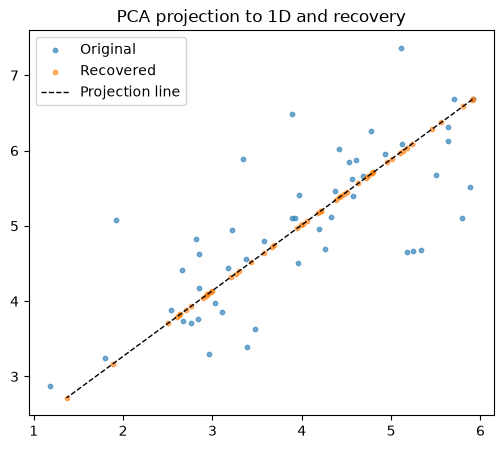

In [4]:
from scipy.io import loadmat
import numpy as np
import matplotlib.pyplot as plt

try:
    X = loadmat('ex7data1.mat').get('X', None)
    if X is None:
        raise FileNotFoundError('X not found in mat file')
except Exception as e:
    # Fallback synthetic data
    rng = np.random.default_rng(0)
    t = rng.normal(size=300)
    X = np.c_[t, 0.4*t + rng.normal(scale=0.2, size=t.shape)]

m, n = X.shape
# The mean and standard deviation of each column (feature).
mu = X.mean(axis=0)
sigma = X.std(axis=0)
# Normalized features: mean 0 and standard deviation 1 in each column.
X_norm = (X - mu) / sigma

# Covariance matrix (2 x 2): how the two normalized features vary together.
Sigma = (X_norm.T @ X_norm) / m
# By hand: Sigma[0, 1] = np.mean(X_norm[:, 0] * X_norm[:, 1])
# SVD gives the principal directions (columns of U) and their variances (S).
U, S, Vt = np.linalg.svd(Sigma)

# Project to 1D and recover
# U1 is the first principal direction, kept as a (2, 1) column.
U1 = U[:, :1]
# Z is the 1D value of each point along that direction.
Z = X_norm @ U1
# I go back to 2D in normalized units...
X_rec = Z @ U1.T
# ...then undo the normalization to return to the original units.
X_rec = X_rec * sigma + mu

print('Shapes: X', X.shape, '| Z', Z.shape, '| X_rec', X_rec.shape)
print('First principal component:', U1.ravel())
print('Share of the variance kept by the first component:', round(S[0] / S.sum(), 3))

plt.figure(figsize=(6,5))
plt.scatter(X[:,0], X[:,1], s=10, alpha=0.6, label='Original')
plt.scatter(X_rec[:,0], X_rec[:,1], s=10, alpha=0.6, label='Recovered')
# The recovered points all lie on one line, the projection line.
# I sort them by Z so the line is drawn from one end to the other.
order = np.argsort(Z[:, 0])
plt.plot(X_rec[order, 0], X_rec[order, 1], 'k--', linewidth=1, label='Projection line')
plt.title('PCA projection to 1D and recovery')
plt.legend(); plt.show()

**My result:** The printed first principal component is about `[-0.707, -0.707]`, a diagonal direction, because the two features grow together. The first component keeps **0.868** (about 87%) of the variance, so going from 2 features to 1 loses only about 13% of the information. In the plot, all the recovered points lie on the dashed projection line, and each one is the closest point on that line to its original point (in normalized units). The distance between an original point and its recovered point is the information that PCA dropped.